# Etapa 2: Preparação e integração dos dados

In [3]:
import sys, json
from pathlib import Path

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

from src import config, coleta, integracao

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

COR = {"exp": "#2a78d6", "imp": "#eb6834", "aqua": "#1baf7a", "violeta": "#6250d6",
       "neutro": "#8f8e88", "texto": "#0b0b0b", "texto2": "#52514e", "grade": "#e4e3df", "fundo": "#fcfcfb"}
mpl.rcParams.update({
    "figure.facecolor": COR["fundo"], "axes.facecolor": COR["fundo"], "savefig.facecolor": COR["fundo"],
    "axes.edgecolor": COR["grade"], "axes.labelcolor": COR["texto2"], "axes.titlecolor": COR["texto"],
    "xtick.color": COR["texto2"], "ytick.color": COR["texto2"], "text.color": COR["texto"],
    "axes.grid": True, "grid.color": COR["grade"], "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "font.size": 10, "legend.frameon": False, "figure.dpi": 110,
})
FIG = RAIZ / "reports" / "figuras"
FIG.mkdir(parents=True, exist_ok=True)

## 1. Execução do pipeline

In [4]:
coleta.coletar_tudo()
bases = integracao.construir_tudo()

ons_intercambio_internacional_horario: 627,017 linhas
ons_ena_subsistema_diario: 36,528 linhas
ons_ear_subsistema_diario: 36,528 linhas
ons_carga_subsistema_diario: 36,528 linhas
ons_cmo_semanal: 4,172 linhas
ons_vertida_turbinavel_diario: 14,608 linhas
clima_diario_cidades: 73,056 linhas
clima_diario_grupos: 9,132 linhas
macro_cambio_diario: 8,338 linhas
macro_atividade_mensal: 516 linhas
calendario_diario: 9,163 linhas
base horária: 217,373 linhas x 14 colunas
base diária: 9,132 linhas x 72 colunas
base modelagem t+1: 3,652 linhas x 47 colunas


## 2. Fontes e cobertura

In [5]:
I = config.INTERMEDIARIOS
def cobertura(nome, arquivo, col_data):
    df = pd.read_parquet(I / arquivo)
    return {"fonte": nome, "linhas": len(df), "início": df[col_data].min().date(), "fim": df[col_data].max().date(),
            "% ausentes (valores)": round(100 * df.select_dtypes("number").isna().mean().mean(), 3)}

pd.DataFrame([
    cobertura("Intercâmbio internacional (3 países)", "ons_intercambio_internacional_horario.parquet", "din_instante"),
    cobertura("ENA por subsistema", "ons_ena_subsistema_diario.parquet", "data"),
    cobertura("EAR por subsistema", "ons_ear_subsistema_diario.parquet", "data"),
    cobertura("Vertida turbinável (agregada)", "ons_vertida_turbinavel_diario.parquet", "data"),
    cobertura("Carga por subsistema", "ons_carga_subsistema_diario.parquet", "data"),
    cobertura("CMO semanal", "ons_cmo_semanal.parquet", "data_referencia_semana"),
    cobertura("Clima (8 cidades)", "clima_diario_cidades.parquet", "data"),
    cobertura("Câmbio", "macro_cambio_diario.parquet", "data"),
    cobertura("IBC-Br e EMAE", "macro_atividade_mensal.parquet", "mes_referencia"),
    cobertura("Calendário", "calendario_diario.parquet", "data"),
])

,fonte,linhas,início,fim,% ausentes (valores)
0,Intercâmbio internacional (3 países),627017,2000-01-01,2024-12-31,0.00
1,ENA por subsistema,36528,2000-01-01,2024-12-31,0.00
2,EAR por subsistema,36528,2000-01-01,2024-12-31,0.00
3,Vertida turbinável (agregada),14608,2015-01-01,2024-12-31,0.00
4,Carga por subsistema,36528,2000-01-01,2024-12-31,0.04
5,CMO semanal,4172,2005-01-07,2024-12-27,0.00
6,Clima (8 cidades),73056,2000-01-01,2024-12-31,0.00
7,Câmbio,8338,2002-03-05,2024-12-31,0.00
8,IBC-Br e EMAE,516,2003-01-01,2024-12-01,0.00
9,Calendário,9163,2000-01-01,2025-01-31,0.00


## 3. Variável-alvo

In [6]:
h = bases["horaria"]
por_dia = h.groupby("data").size()
idx = pd.date_range("2000-01-01", "2024-12-31")
faltantes = idx.difference(por_dia.index)
print("Registros horários (Argentina):", f"{len(h):,}")
print("Horas por dia:", por_dia.value_counts().to_dict(), "→ dias com 23 h = início do horário de verão")
print("Duplicidades (instante):", h["din_instante"].duplicated().sum())
s = pd.Series(faltantes)
blocos = s.groupby((s.diff() != pd.Timedelta("1D")).cumsum()).agg(["min", "max", "count"])
blocos.columns = ["início", "fim", "dias"]
print("\nDias sem nenhum registro no ONS:")
blocos

Registros horários (Argentina): 217,373
Horas por dia: {24: 9039, 23: 19} → dias com 23 h = início do horário de verão
Duplicidades (instante): 0

Dias sem nenhum registro no ONS:


,início,fim,dias
1,2008-12-05,2009-02-13,71
2,2013-12-01,2013-12-01,1
3,2014-02-01,2014-02-01,1
4,2015-04-09,2015-04-09,1


In [7]:
d = bases["diaria"].set_index("data")
anual = d.groupby(d.index.year).agg(
    media_mwmed=("intercambio_mwmed", "mean"),
    magnitude_media=("intercambio_abs_mwmed", "mean"),
    pct_dias_exportacao=("sentido_dia", lambda s: 100 * (s == "exportacao").mean()),
    pct_dias_importacao=("sentido_dia", lambda s: 100 * (s == "importacao").mean()),
    pct_dias_sem_fluxo=("sentido_dia", lambda s: 100 * (s == "sem_fluxo").mean()),
    minimo=("intercambio_mwmed", "min"), maximo=("intercambio_mwmed", "max"))
anual.index.name = "ano"
anual.round(1)

,media_mwmed,magnitude_media,pct_dias_exportacao,pct_dias_importacao,pct_dias_sem_fluxo,minimo,maximo
ano,,,,,,,
2000,-371.60,372.50,4.90,61.20,33.90,"-1,025.40",58.10
2001,-450.80,452.10,4.10,62.50,33.40,"-1,097.00",92.90
2002,-47.00,48.30,6.80,16.20,77.00,"-1,001.70",79.60
2003,0.20,0.50,5.50,2.20,92.30,-13.00,33.20
2004,121.00,124.10,39.30,2.70,57.90,-192.50,506.00
2005,-2.00,108.00,21.90,22.50,55.60,-743.20,613.60
2006,56.40,80.10,21.10,9.30,69.60,-345.30,577.90
2007,211.40,242.70,34.80,7.90,57.30,-703.60,"1,056.50"
2008,69.80,253.40,24.60,10.70,57.40,"-1,924.50","1,290.80"


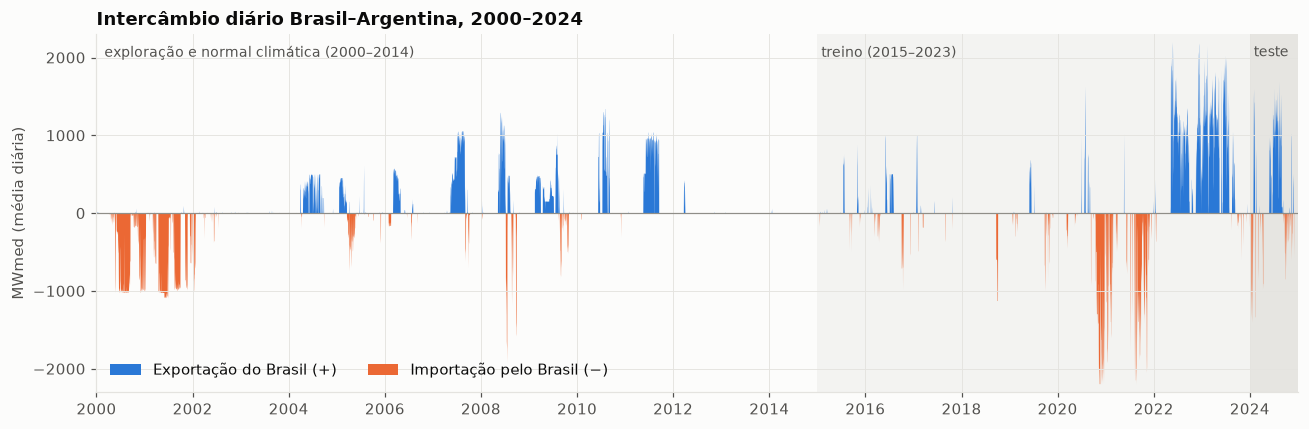

In [8]:
y = d["intercambio_mwmed"]
fig, ax = plt.subplots(figsize=(12, 4))
ax.fill_between(y.index, 0, y.clip(lower=0), color=COR["exp"], linewidth=0, label="Exportação do Brasil (+)")
ax.fill_between(y.index, 0, y.clip(upper=0), color=COR["imp"], linewidth=0, label="Importação pelo Brasil (−)")
ax.axhline(0, color=COR["neutro"], linewidth=0.8)
for ini, fim, rot, alfa in [("2015-01-01", "2023-12-31", "treino (2015–2023)", 0.35), ("2024-01-01", "2024-12-31", "teste", 0.9)]:
    ax.axvspan(pd.Timestamp(ini), pd.Timestamp(fim), color=COR["grade"], alpha=alfa, zorder=0, linewidth=0)
    ax.text(pd.Timestamp(ini) + pd.Timedelta(days=30), 2150, rot, color=COR["texto2"], fontsize=9, va="top")
ax.text(pd.Timestamp("2000-03-01"), 2150, "exploração e normal climática (2000–2014)", color=COR["texto2"], fontsize=9, va="top")
ax.set_ylim(-2300, 2300)
ax.set_xlim(pd.Timestamp("2000-01-01"), pd.Timestamp("2025-01-01"))
ax.set_ylabel("MWmed (média diária)")
ax.set_title("Intercâmbio diário Brasil–Argentina, 2000–2024")
ax.legend(loc="lower left", ncol=2)
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout(); fig.savefig(FIG / "01_intercambio_diario.png", dpi=150); plt.show()

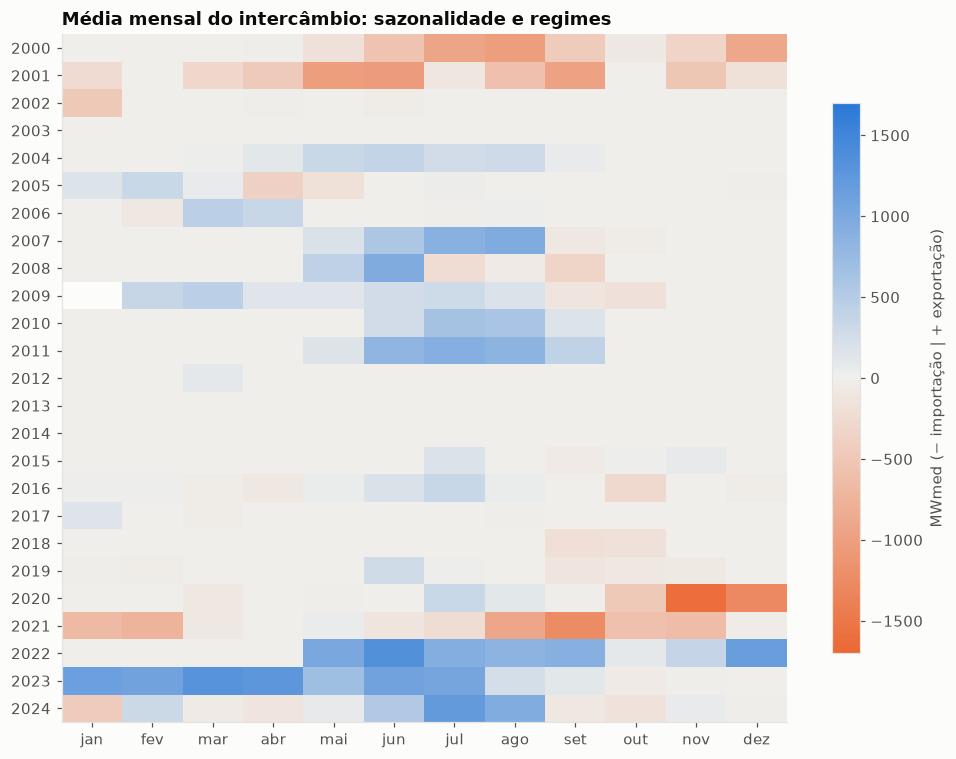

In [9]:
mensal = y.groupby([y.index.year, y.index.month]).mean().unstack()
cmap = LinearSegmentedColormap.from_list("div", [COR["imp"], "#f0efec", COR["exp"]])
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(mensal.values, aspect="auto", cmap=cmap, norm=TwoSlopeNorm(vmin=-1700, vcenter=0, vmax=1700))
ax.set_xticks(range(12), ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"])
ax.set_yticks(range(len(mensal.index)), mensal.index)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.8)
cb.set_label("MWmed (− importação | + exportação)")
ax.set_title("Média mensal do intercâmbio: sazonalidade e regimes")
fig.tight_layout(); fig.savefig(FIG / "02_mapa_mensal.png", dpi=150); plt.show()

## 4. Clima

In [10]:
lim = pd.read_csv(config.INTERMEDIARIOS / "clima_limiares_extremos.csv")
display(lim)
cg = pd.read_parquet(config.INTERMEDIARIOS / "clima_diario_grupos.parquet").set_index("data")
ext = pd.DataFrame({
    "dias quentes extremos BR": cg["clima_br_extremo_quente"], "dias frios extremos BR": cg["clima_br_extremo_frio"],
    "dias quentes extremos AR": cg["clima_ar_extremo_quente"], "dias frios extremos AR": cg["clima_ar_extremo_frio"],
}).groupby(cg.index.year).sum()
ext.loc[2015:]

,grupo,p90_tmax_verao,p10_tmin_inverno
0,br,30.76,11.07
1,br_se,31.18,11.63
2,br_s,29.82,6.20
3,ar,31.33,3.44


,dias quentes extremos BR,dias frios extremos BR,dias quentes extremos AR,dias frios extremos AR
data,,,,
2015,24,0,6,5
2016,13,17,10,6
2017,8,9,17,5
2018,4,6,15,12
2019,16,12,13,10
2020,3,6,9,13
2021,6,16,11,6
2022,1,12,17,9
2023,8,4,20,9


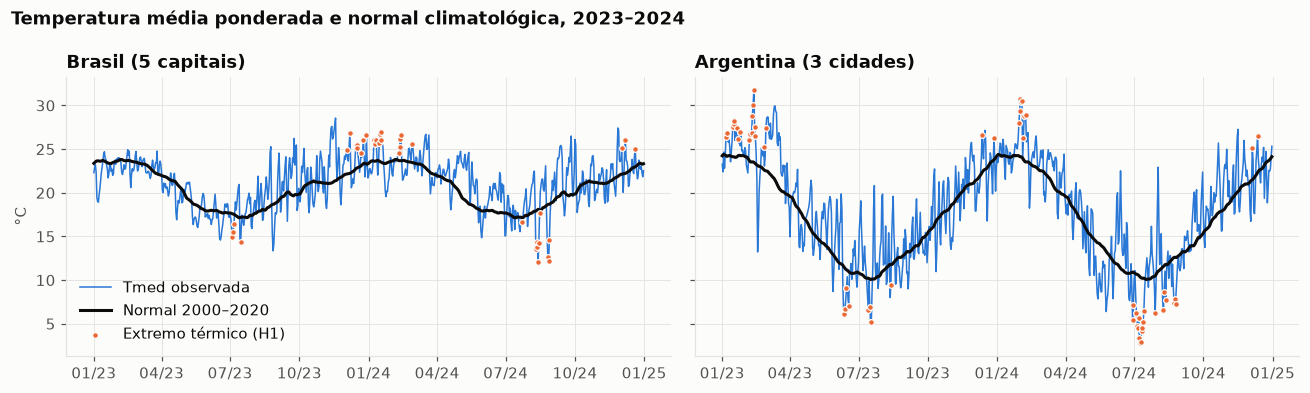

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, g, nome in zip(axes, ["br", "ar"], ["Brasil (5 capitais)", "Argentina (3 cidades)"]):
    s = cg.loc["2023-01-01":"2024-12-31", f"clima_{g}_tmed"]
    normal = s - cg.loc[s.index, f"clima_{g}_anom_tmed"]
    ax.plot(s.index, s, color=COR["exp"], linewidth=1, label="Tmed observada")
    ax.plot(normal.index, normal, color=COR["texto"], linewidth=2, label="Normal 2000–2020")
    q = cg.loc[s.index, f"clima_{g}_extremo_termico"] == 1
    ax.scatter(s.index[q], s[q], s=14, color=COR["imp"], zorder=3, label="Extremo térmico (H1)",
               edgecolor=COR["fundo"], linewidth=0.8)
    ax.set_title(nome); ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))
axes[0].set_ylabel("°C"); axes[0].legend(loc="lower left")
fig.suptitle("Temperatura média ponderada e normal climatológica, 2023–2024", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "03_normal_climatologica.png", dpi=150); plt.show()

## 5. Calendário

In [12]:
cal = pd.read_parquet(config.INTERMEDIARIOS / "calendario_diario.parquet")
c = cal[(cal.ano >= 2015) & (cal.ano <= 2024)]
display(c.groupby("ano")[["feriado_br", "ponto_facultativo_br", "feriado_ar", "dia_util_ambos", "ferias_escolares_ar"]].sum())
c24 = cal[(cal.ano == 2024) & ((cal.feriado_br == 1) | (cal.feriado_ar == 1) | (cal.ponto_facultativo_br == 1))]
c24[["data", "dia_semana", "feriado_br", "nome_feriado_br", "ponto_facultativo_br", "feriado_ar", "nome_feriado_ar"]]

,feriado_br,ponto_facultativo_br,feriado_ar,dia_util_ambos,ferias_escolares_ar
ano,,,,,
2015,9,7,17,237,83
2016,9,7,18,239,84
2017,9,7,17,240,83
2018,9,7,20,238,83
2019,9,7,20,241,83
2020,9,7,20,235,84
2021,9,7,19,236,83
2022,9,7,22,236,83
2023,9,7,20,237,83


,data,dia_semana,feriado_br,nome_feriado_br,ponto_facultativo_br,feriado_ar,nome_feriado_ar
8766,2024-01-01,0,1,Confraternização Universal,0,1,Año Nuevo
8808,2024-02-12,0,0,,1,1,Lunes de Carnaval
8809,2024-02-13,1,0,,1,1,Martes de Carnaval
8810,2024-02-14,2,0,,1,0,
8849,2024-03-24,6,0,,0,1,Día Nacional de la Memoria por la Verdad y la ...
8853,2024-03-28,3,0,,0,1,Jueves Santo
8854,2024-03-29,4,1,Sexta-feira Santa,0,1,Viernes Santo
8857,2024-04-01,0,0,,0,1,Feriado con fines turísticos
8858,2024-04-02,1,0,,0,1,Día del Veterano y de los Caidos en la Guerra ...
8877,2024-04-21,6,1,Tiradentes,0,0,


## 6. Alinhamento do CMO semanal

In [13]:
arqs = [coleta.baixar(f"https://ons-aws-prod-opendata.s3.amazonaws.com/dataset/cmo_tm/CMO_SEMIHORARIO_{a}.csv",
                       config.BRUTOS / "ons" / "cmo_semihorario" / f"CMO_SEMIHORARIO_{a}.csv") for a in (2021, 2022)]
sh = pd.concat([pd.read_csv(a, sep=";") for a in arqs])
sh["din_instante"] = pd.to_datetime(sh["din_instante"])
sh = sh[sh["id_subsistema"].str.strip() == "SE"]
dia_sh = sh.groupby(sh["din_instante"].dt.normalize())["val_cmo"].mean()
sem = pd.read_parquet(config.INTERMEDIARIOS / "ons_cmo_semanal.parquet")
sem = sem[(sem.id_subsistema == "SE") & sem.data_referencia_semana.dt.year.isin([2021, 2022])]
comp = pd.DataFrame([{
    "cmo_semanal": r.cmo_medio_semanal,
    "semana que TERMINA na sexta": dia_sh.loc[r.data_referencia_semana - pd.Timedelta(days=6): r.data_referencia_semana].mean(),
    "semana que COMEÇA após a sexta": dia_sh.loc[r.data_referencia_semana + pd.Timedelta(days=1): r.data_referencia_semana + pd.Timedelta(days=7)].mean(),
} for r in sem.itertuples()]).dropna()
comp.corr().round(3).iloc[[0]]

,cmo_semanal,semana que TERMINA na sexta,semana que COMEÇA após a sexta
cmo_semanal,1.00,1.00,0.93


## 7. Base diária integrada

In [14]:
diaria = bases["diaria"]
print("Dimensão:", diaria.shape, "| datas únicas:", diaria["data"].is_unique,
      "|", diaria["data"].min().date(), "a", diaria["data"].max().date())
prefixos = {"alvo": ["intercambio", "intensidade", "horas_", "valor_ultima", "media_ultimas", "sentido_dia"],
            "clima": ["clima_"], "hidrologia": ["hidro_"], "preço": ["preco_"], "carga": ["carga_"], "macro": ["macro_"]}
linhas = []
for bloco, pref in prefixos.items():
    cols = [c for c in diaria.columns if any(c.startswith(p) for p in pref)]
    linhas.append({"bloco": bloco, "colunas": len(cols),
                   **{f"% ausente ({p})": round(100 * diaria.loc[diaria.periodo == p, cols].isna().mean().mean(), 2)
                      for p in ["exploracao", "treino", "teste"]}})
pd.DataFrame(linhas)

Dimensão: (9132, 72) | datas únicas: True | 2000-01-01 a 2024-12-31


,bloco,colunas,% ausente (exploracao),% ausente (treino),% ausente (teste)
0,alvo,7,1.33,0.03,0.00
1,clima,36,0.00,0.00,0.00
2,hidrologia,7,28.57,0.01,0.00
3,preço,1,33.35,0.00,1.09
4,carga,2,0.05,0.03,0.00
5,macro,3,24.83,0.00,0.00


## 8. Base de modelagem t+1

In [15]:
modelo = bases["modelagem"]
grupos = json.loads((config.PROCESSADOS / "grupos_variaveis.json").read_text())
print("Dimensão:", modelo.shape)
print(modelo["particao"].value_counts().to_dict())
display(pd.Series({k: len(v) for k, v in grupos.items()}, name="atributos por bloco").to_frame().T)
modelo[["data", "alvo_intercambio_mwmed", "hist_lag1", "hist_media_ult6h_l1", "cal_feriado_br",
        "clima_ar_hdd_7d", "hidro_ear_pct_s_l1", "preco_cmo_s_ult_semana", "macro_ars_usd_var30", "particao"]].tail()

Dimensão: (3652, 47)
{'treino': 3286, 'teste': 366}


,historico,calendario,clima,hidro_preco,carga,macro
atributos por bloco,8,9,10,9,2,3


,data,alvo_intercambio_mwmed,hist_lag1,hist_media_ult6h_l1,cal_feriado_br,clima_ar_hdd_7d,hidro_ear_pct_s_l1,preco_cmo_s_ult_semana,macro_ars_usd_var30,particao
3647,2024-12-27,0.00,0.00,0.00,0,0.00,78.93,1.71,2.09,teste
3648,2024-12-28,0.00,0.00,0.00,0,0.00,79.18,2.69,2.13,teste
3649,2024-12-29,0.00,0.00,0.00,0,0.00,79.36,2.69,2.08,teste
3650,2024-12-30,0.00,0.00,0.00,0,0.00,79.38,2.69,1.84,teste
3651,2024-12-31,0.00,0.00,0.00,0,0.00,79.37,2.69,2.03,teste


## 9. Variáveis recomendadas

In [16]:
recom = config.VARIAVEIS
treino = modelo[modelo["particao"] == "treino"]
y = treino["alvo_intercambio_mwmed"]
tab = pd.DataFrame([{"bloco": b, "variável": c,
                     "ρ com y": treino[c].corr(y, method="spearman"),
                     "ρ com |y|": treino[c].corr(y.abs(), method="spearman")}
                    for b, cols in recom.items() for c in cols])
print("Total:", len(tab))
with pd.option_context("display.max_rows", 60):
    display(tab.round(2))

Total: 41


,bloco,variável,ρ com y,ρ com |y|
0,historico,hist_media_ult6h_l1,0.88,0.22
1,historico,hist_lag1,0.87,0.20
2,historico,hist_horas_import_l1,-0.59,0.41
3,historico,hist_lag2,0.81,0.22
4,historico,hist_horas_export_l1,0.73,0.63
5,historico,hist_abs_mm7,0.17,0.74
6,historico,hist_mm7,0.77,0.17
7,historico,hist_lag7,0.69,0.20
8,calendario,cal_mes,-0.12,0.07
9,calendario,cal_cos_anual,-0.20,-0.02


In [17]:
cam = pd.read_parquet(config.INTERMEDIARIOS / "macro_cambio_diario.parquet")
cam = cam[cam["data"].dt.year.between(2015, 2023)]
cam.groupby(cam["data"].dt.year)["ars_usd"].mean().round(1).to_frame("ARS por US$ (média anual)")

,ARS por US$ (média anual)
data,
2015,9.30
2016,14.80
2017,16.60
2018,28.10
2019,48.20
2020,70.60
2021,95.10
2022,130.70
2023,296.50


Dias do treino em que o fluxo médio não mudou em relação a ontem: 67%


,persistência y(d−1),sazonal y(d−7),prever zero
ano,,,
2020,97.40,228.70,335.00
2021,200.80,404.30,435.10
2022,119.30,276.00,562.10
2023,151.60,345.40,670.90


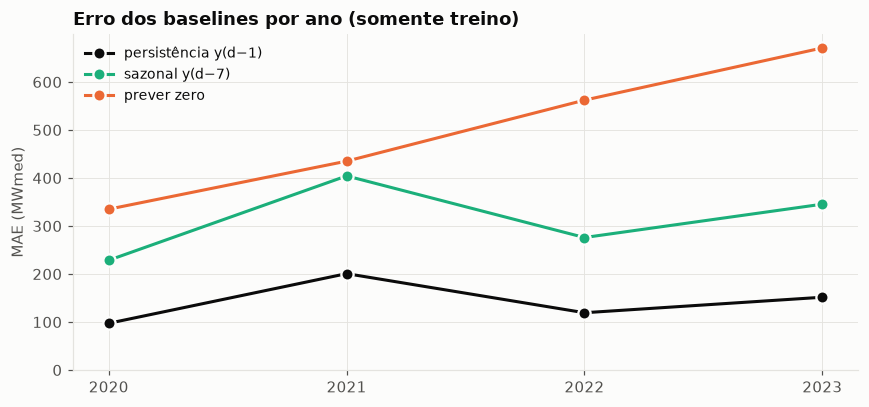

In [18]:
val = treino.assign(ano=treino["data"].dt.year).query("ano >= 2020")
mae = lambda prev: (val["alvo_intercambio_mwmed"] - prev.fillna(0)).abs().groupby(val["ano"]).mean()
base = pd.DataFrame({"persistência y(d−1)": mae(val["hist_lag1"]),
                     "sazonal y(d−7)": mae(val["hist_lag7"]),
                     "prever zero": mae(pd.Series(0.0, index=val.index))})
sem_mudanca = ((treino["alvo_intercambio_mwmed"] - treino["hist_lag1"]).abs() < 1).mean()
print(f"Dias do treino em que o fluxo médio não mudou em relação a ontem: {100 * sem_mudanca:.0f}%")
display(base.round(1))

fig, ax = plt.subplots(figsize=(8, 3.8))
for col, cor in zip(base.columns, [COR["texto"], COR["aqua"], COR["imp"]]):
    ax.plot(base.index, base[col], marker="o", markersize=8, linewidth=2, color=cor, label=col,
            markeredgecolor=COR["fundo"], markeredgewidth=1.5)
ax.set_xticks(base.index); ax.set_ylabel("MAE (MWmed)"); ax.set_ylim(0, None)
ax.set_title("Erro dos baselines por ano (somente treino)")
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "04_baselines.png", dpi=150); plt.show()